# Personas e priorização · Vitaliza · Grupo 2

**Pergunta desta etapa:** dos cinco segmentos de 31/07/2026, quais viram persona, onde cada uma fica na matriz valor × risco e quanto do orçamento de CRM vai para cada uma?

Seguimos o roteiro da Aula 5 (prof. Fábio, 10/11): validar cada persona (n, saída do grupo contra a do resto, diferença em pontos percentuais e cobertura), medir o valor, classificar os dois eixos e posicionar. Acrescentamos um passo que o roteiro não tinha e o case pede: a campanha de agosto, o único experimento sorteado da base, que mostra se o contato muda a saída de cada persona.

Este trabalho está no branch `personas-v1` e entra na `main` por pull request.

In [1]:
from pathlib import Path
import math
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
BRUTOS, PROC, FIGS = RAIZ / "dados" / "brutos", RAIZ / "dados" / "processados", RAIZ / "saidas" / "personas"
FIGS.mkdir(parents=True, exist_ok=True)

CORTE = pd.Timestamp("2026-08-01")        # pagantes ativos em 31/07/2026 (fim do dia), como na segmentação
FIM_SAIDA = CORTE + pd.Timedelta(days=60) # saída em 60 dias: até 29/09/2026
CAMPANHA = pd.Timestamp("2026-08-10")     # envio da campanha de retenção
ORDEM = ["Ativos ao ar livre", "Ativos em ambiente fechado", "Novatos", "Esporádicos", "Parados"]
CORES = {"Ativos ao ar livre": "#2f7d4f", "Ativos em ambiente fechado": "#2d5fa8", "Novatos": "#c98a1b",
         "Esporádicos": "#d6453d", "Parados": "#6b6b6b"}

# números do enunciado do case (seção 03)
CAC, CUSTO_SERVIR = 118.00, 4.20
LIQ_MENSAL = {"app_store": 33.92, "google_play": 33.92, "web_cartao": 38.50, "web_pix": 39.50}
LIQ_ANUAL = {"app_store": 254.92, "google_play": 254.92, "web_cartao": 299.90 * (1 - 0.035), "web_pix": 299.90 * (1 - 0.0099)}
CUSTO = {"push": 0.0, "email": 0.01, "whatsapp": 0.40, "cs": 18.00, "cupom_mensal": 35.91, "cupom_anual": 25.00}
TETO = {"whatsapp": 1500, "cs": 300, "orcamento": 40000}

## Passo 0 · As tabelas

Partimos dos segmentos gravados pela segmentação (`segmentos_31jul.csv`, com saída em 60 dias e "podia sair") e das variáveis de comportamento. Do data room, usamos só o que a pergunta pede: eventos de assinatura (canal de cobrança e renovação desligada), usuários (canal de aquisição), pagamentos (valor já pago), a rede de seguidores e a campanha de agosto.

In [2]:
seg = pd.read_csv(PROC / "segmentos_31jul.csv").set_index("user_id")
var = pd.read_csv(PROC / "variaveis_31jul.csv").set_index("user_id")
seg = seg.join(var)
seg["segmento"] = pd.Categorical(seg["segmento"], ORDEM)
eventos = pd.read_csv(PROC / "eventos_assinatura.csv", parse_dates=["data_hora_brt"])
usuarios = pd.read_csv(PROC / "usuarios.csv", usecols=["user_id", "canal_aquisicao"]).set_index("user_id")
pagamentos = pd.read_csv(BRUTOS / "pagamentos.csv", dtype={"valor": str})
amizades = pd.read_csv(BRUTOS / "amizades.csv", parse_dates=["desde"])
campanha = pd.read_csv(BRUTOS / "campanha_ago26.csv").set_index("user_id")
for nome, t in [("segmentos 31/07", seg), ("eventos", eventos), ("usuários", usuarios), ("pagamentos", pagamentos),
                ("amizades", amizades), ("campanha", campanha)]:
    print(f"{nome:<16} {len(t):>9,} linhas")

segmentos 31/07     14,032 linhas
eventos            275,565 linhas
usuários            64,888 linhas
pagamentos         165,548 linhas
amizades           113,480 linhas
campanha            14,120 linhas


## Passo 1 · Atributos de valor e de sinal

Para cada pagante de 31/07, com informação só até essa data:
- **canal de cobrança** e **plano**: o último evento pago antes do corte;
- **renovação desligada**: o último aviso antes do corte foi `renovacao_automatica_desligada` (sem religar depois);
- **veio por indicação**: `canal_aquisicao = indicacao`;
- **seguidores**: quantas pessoas o seguiam em 31/07;
- **valor já pago**: soma das cobranças aprovadas até 31/07.

**Limpeza encontrada:** 19.750 linhas de `pagamentos.csv` têm o valor como texto ("R$ 34,90"). Convertemos para número; o valor não muda.

In [3]:
antes = eventos[eventos["data_hora_brt"] < CORTE].sort_values("data_hora_brt")
seg["canal"] = antes[antes["canal_cobranca"].notna()].groupby("user_id")["canal_cobranca"].last().reindex(seg.index)
aviso = antes[antes["evento"].isin(["renovacao_automatica_desligada", "renovacao_automatica_religada"])].groupby("user_id")["evento"].last()
seg["renov_desligada"] = aviso.reindex(seg.index).eq("renovacao_automatica_desligada")
seg["indicacao"] = usuarios["canal_aquisicao"].reindex(seg.index).eq("indicacao")
seg["seguidores"] = amizades[amizades["desde"] < CORTE].groupby("seguido_id").size().reindex(seg.index).fillna(0)

texto = pagamentos["valor"].str.startswith("R$")
print(f"valores em texto ('R$ ...'): {texto.sum():,} de {len(pagamentos):,}")
pagamentos["valor"] = pd.to_numeric(pagamentos["valor"].str.replace("R$ ", "", regex=False).str.replace(",", ".", regex=False))
pagamentos["data"] = pd.to_datetime(pagamentos["data_hora"].str.replace("Z", "", regex=False), format="ISO8601")
pagos = pagamentos[(pagamentos["status"] == "aprovado") & (pagamentos["data"] < CORTE)]
print(f"cobranças aprovadas até 31/07: {len(pagos):,}")
seg["pago_ate_corte"] = pagos.groupby("user_id")["valor"].sum().reindex(seg.index).fillna(0)

# margem de 12 meses se a pessoa ficar: receita líquida do canal menos o custo de servir
liq_mes = np.where(seg["plano"] == "anual", seg["canal"].map(LIQ_ANUAL) / 12, seg["canal"].map(LIQ_MENSAL))
seg["margem_12m"] = (liq_mes - CUSTO_SERVIR) * 12
seg["valor_potencial"] = seg["margem_12m"] + CAC
print("sem canal de cobrança:", seg["canal"].isna().sum())
seg[["canal", "plano", "renov_desligada", "indicacao", "seguidores", "pago_ate_corte", "margem_12m", "valor_potencial"]].head()

valores em texto ('R$ ...'): 19,750 de 165,548


cobranças aprovadas até 31/07: 147,779
sem canal de cobrança: 0


,canal,plano,renov_desligada,indicacao,seguidores,pago_ate_corte,margem_12m,valor_potencial
user_id,,,,,,,,
u_0001651d,app_store,mensal,False,False,0.00,688.10,356.64,474.64
u_00130058,google_play,anual,True,True,2.00,599.80,204.52,322.52
u_00158d85,web_cartao,mensal,False,False,1.00,159.60,411.60,529.60
u_00159c6c,web_cartao,mensal,False,False,2.00,618.30,411.60,529.60
u_0016e5e6,app_store,anual,False,False,0.00,299.90,204.52,322.52


## Passo 2 · Validar cada persona

A comparação é sempre **entre quem podia sair** na janela (mensal, ou anual com renovação entre 01/08 e 29/09): o anual no meio do contrato não tem como sair, e misturá-lo esconderia o risco (o "churn diferido" do glossário da Aula 3).

Para cada segmento: n, % da base, saída do grupo, saída do resto, diferença em pontos percentuais e cobertura (% de todas as saídas).

In [4]:
pode = seg[seg["podia_sair"]]
print(f"pagantes em 31/07: {len(seg):,} | podiam sair na janela: {len(pode):,} | saíram: {pode['saiu_60d'].sum():,} ({pode['saiu_60d'].mean():.1%})")

def validar(mascara, nome):
    g, r = pode[mascara], pode[~mascara]
    return {"recorte": nome, "n (podia sair)": len(g), "saída grupo %": g["saiu_60d"].mean() * 100,
            "saída resto %": r["saiu_60d"].mean() * 100,
            "diferença pp": (g["saiu_60d"].mean() - r["saiu_60d"].mean()) * 100,
            "cobertura %": g["saiu_60d"].sum() / pode["saiu_60d"].sum() * 100}

val = pd.DataFrame([validar(pode["segmento"] == s, s) for s in ORDEM]).set_index("recorte")
val.insert(0, "n na base", seg["segmento"].value_counts().reindex(ORDEM).values)
val.insert(1, "% da base", val["n na base"] / len(seg) * 100)
val.round(1)

pagantes em 31/07: 14,032 | podiam sair na janela: 7,089 | saíram: 1,459 (20.6%)


,n na base,% da base,n (podia sair),saída grupo %,saída resto %,diferença pp,cobertura %
recorte,,,,,,,
Ativos ao ar livre,4746,33.80,2560,13.00,24.90,-11.90,22.80
Ativos em ambiente fechado,3929,28.00,2229,11.00,25.00,-13.90,16.90
Novatos,1664,11.90,1027,18.10,21.00,-2.90,12.70
Esporádicos,2858,20.40,1037,51.80,15.20,36.50,36.80
Parados,835,6.00,236,66.90,19.00,48.00,10.80


**Recortes mais finos.** Testamos dois refinamentos antes de fechar as personas:
- **Novatos:** o exemplo do professor era o novato que não se conectou. Na Vitaliza, os novatos saem *menos* que o resto. Será que o novato parado há 8 dias ou mais (o limiar da análise exploratória) separa?
- **Esporádicos:** onde está o risco dentro do grupo? Separamos pelo aviso de renovação desligada e pelo limiar de 8 dias.

In [5]:
nov = pode["segmento"] == "Novatos"
esp = pode["segmento"] == "Esporádicos"
refino = pd.DataFrame([
    validar(nov, "Novatos (todos os que podiam sair)"),
    validar(nov & (pode["dias_sem_treino"] >= 8), "Novatos com 8+ dias sem treino"),
    validar(esp, "Esporádicos (todos os que podiam sair)"),
    validar(esp & (pode["dias_sem_treino"] >= 8), "Esporádicos com 8+ dias sem treino"),
    validar(esp & pode["renov_desligada"], "Esporádicos com a renovação já desligada"),
    validar(esp & ~pode["renov_desligada"], "Esporádicos com a renovação ligada"),
]).set_index("recorte")
print("todos os novatos que podiam sair são mensais:", (pode.loc[nov, "plano"] == "mensal").all())
refino.round(1)

todos os novatos que podiam sair são mensais: True


,n (podia sair),saída grupo %,saída resto %,diferença pp,cobertura %
recorte,,,,,
Novatos (todos os que podiam sair),1027,18.10,21.00,-2.90,12.70
Novatos com 8+ dias sem treino,115,27.00,20.50,6.50,2.10
Esporádicos (todos os que podiam sair),1037,51.80,15.20,36.50,36.80
Esporádicos com 8+ dias sem treino,740,62.60,15.70,46.90,31.70
Esporádicos com a renovação já desligada,451,96.20,15.40,80.80,29.70
Esporádicos com a renovação ligada,586,17.60,20.90,-3.30,7.10


In [6]:
desl = pode[pode["renov_desligada"]]
print(f"renovação desligada em 31/07 (todos os segmentos): {len(desl):,} que podiam sair; "
      f"saída {desl['saiu_60d'].mean():.1%}; {desl['saiu_60d'].sum() / pode['saiu_60d'].sum():.1%} de todas as saídas")
pode.groupby(["segmento", "renov_desligada"], observed=True)["saiu_60d"].agg(["size", "mean"]).round(3)

renovação desligada em 31/07 (todos os segmentos): 783 que podiam sair; saída 96.7%; 51.9% de todas as saídas


size  mean
segmento                   renov_desligada            
Ativos ao ar livre         False            2470  0.10
                           True               90  0.98
Ativos em ambiente fechado False            2158  0.08
                           True               71  0.94
Novatos                    False             990  0.15
                           True               37  1.00
Esporádicos                False             586  0.18
                           True              451  0.96
Parados                    False             102  0.27
                           True              134  0.98

**O que os números dizem.**
- O **novato parado há 8 dias** separa pouco (+6,5 pp) e cobre só 2% das saídas. O novato da Vitaliza não é o novato do exemplo: fica como persona de risco baixo.
- Nos **esporádicos**, o risco está em quem **já desligou a renovação**: 96% saem. Com a renovação ligada, saem 17,6%, abaixo da média. O aviso de renovação desligada não é vazamento (chega antes da saída, por notificação da loja), mas é quase a saída anunciada: o enunciado diz que, para quem paga pela loja, o intervalo entre esse aviso e a expiração é a última chance de agir. Ele vira o **gatilho** da persona, não o seu critério.

## Passo 3 · Valor

O roteiro da Aula 5 pede para declarar o critério de valor. **Declaramos o potencial:** o que a Vitaliza ainda pode receber se a pessoa ficar. Medimos com os critérios do slide (tamanho, tempo de casa, plano e indicação) e em reais, com os números do enunciado:
- **margem de 12 meses** = receita líquida do canal de cobrança (a loja fica com 15%) menos R$ 4,20 por mês de custo de servir;
- **valor potencial** = margem de 12 meses + R$ 118 de CAC, o custo de repor quem sai;
- **valor presente**, para comparar: o que a pessoa já pagou até 31/07.

In [7]:
valor = seg.groupby("segmento", observed=True).agg(
    tempo_casa_dias=("tempo_casa_dias", "median"),
    pct_anual=("plano", lambda s: (s == "anual").mean() * 100),
    pct_indicacao=("indicacao", lambda s: s.mean() * 100),
    seguidores=("seguidores", "median"),
    pago_ate_corte=("pago_ate_corte", "median"),
    margem_12m=("margem_12m", "median"),
    valor_potencial=("valor_potencial", "median"))
valor["% da base"] = seg["segmento"].value_counts(normalize=True).reindex(ORDEM).values * 100
perdido = pode.assign(v=pode["saiu_60d"] * pode["valor_potencial"]).groupby("segmento", observed=True)["v"].sum()
valor["valor perdido em 60 dias (R$)"] = perdido
print(f"base: tempo de casa {seg['tempo_casa_dias'].median():.0f} dias | anual {(seg['plano'] == 'anual').mean():.0%} | "
      f"indicação {seg['indicacao'].mean():.1%} | valor potencial mediano R$ {seg['valor_potencial'].median():.0f}")
valor.round(1)

base: tempo de casa 274 dias | anual 59% | indicação 15.3% | valor potencial mediano R$ 357


,tempo_casa_dias,pct_anual,pct_indicacao,seguidores,pago_ate_corte,margem_12m,valor_potencial,% da base,valor perdido em 60 dias (R$)
segmento,,,,,,,,,
Ativos ao ar livre,303.50,53.00,16.50,2.00,339.10,246.50,364.50,33.80,"158,545.60"
Ativos em ambiente fechado,290.00,49.70,15.10,2.00,304.20,356.60,474.60,28.00,"116,846.60"
Novatos,28.00,38.30,12.60,0.00,79.80,356.60,474.60,11.90,"92,042.40"
Esporádicos,315.00,82.40,16.10,2.00,299.90,204.50,322.50,20.40,"202,274.50"
Parados,506.00,99.20,12.80,2.00,599.80,204.50,322.50,6.00,"53,040.40"


**Leitura.** O anual rende menos por mês (R$ 21 líquidos pela loja, contra R$ 34 do mensal), mas trava a receita de um ano numa cobrança só. Por isso o valor por pessoa dos esporádicos e dos parados é o mais baixo, e mesmo assim os esporádicos são o grupo que mais leva valor embora em 60 dias: são muitos, têm tempo de casa e são 82% anuais. Indicação (12–17%) e seguidores (mediana de 2) quase não variam entre os grupos e não ajudam a separar valor.

**Classificação do valor (critério potencial):**

| Persona | Valor | Por quê |
| :-- | :-- | :-- |
| Esporádicos | alto | 20% da base, 315 dias de casa, 82% anual; maior valor perdido em 60 dias |
| Ativos ao ar livre | alto | maior grupo (34%), 304 dias, metade anual; maior receita mensal da base |
| Ativos em ambiente fechado | alto | 28% da base, 290 dias, metade anual |
| Novatos | médio | 12% da base, 28 dias; CAC recém-pago, mas 62% mensal e pouco histórico |
| Parados | médio | 6% da base; 99% anual, mas pagam por algo que não usam |

## Passo 4 · A campanha de agosto: o contato muda a saída?

Em 10/08, os pagantes do dia foram sorteados em quatro grupos: desafio, cupom e conteúdo (por push e e-mail) e um controle que não recebeu nada. Como o sorteio iguala os grupos, a diferença de saída contra o controle é efeito da mensagem. A empresa nunca analisou o resultado.

Medimos, dentro de cada persona e entre quem podia sair, a saída de 10/08 a 29/09 em cada grupo, com intervalo de confiança de 95%. Antes, conferimos se o sorteio ficou equilibrado entre os segmentos.

In [8]:
fim = eventos[(eventos["data_hora_brt"] >= CAMPANHA) & (eventos["data_hora_brt"] < FIM_SAIDA) & (eventos["evento"] == "assinatura_expirada")]
camp = seg.join(campanha[["grupo"]].rename(columns={"grupo": "braco"}), how="inner")
camp["saiu_pos"] = camp.index.isin(set(fim["user_id"])).astype(int)
print(f"pagantes de 31/07 que estão na campanha: {len(camp):,} de {len(seg):,} (os demais saíram antes de 10/08)")
print("equilíbrio do sorteio (% de cada segmento por braço):")
display((pd.crosstab(camp["segmento"], camp["braco"], normalize="columns") * 100).round(1))

c = camp[camp["podia_sair"]]
def efeito(trat, ctl):
    p1, n1, p0, n0 = trat.mean(), len(trat), ctl.mean(), len(ctl)
    d = p1 - p0
    ep = math.sqrt(p1 * (1 - p1) / n1 + p0 * (1 - p0) / n0)
    return d * 100, (d - 1.96 * ep) * 100, (d + 1.96 * ep) * 100

linhas = []
for nome, d in [*[(s, c[c["segmento"] == s]) for s in ORDEM], ("Base toda", c)]:
    ctl = d.loc[d["braco"] == "controle", "saiu_pos"]
    for b in ["desafio", "cupom", "conteudo"]:
        e, lo, hi = efeito(d.loc[d["braco"] == b, "saiu_pos"], ctl)
        linhas.append({"persona": nome, "mensagem": b, "n": (d["braco"] == b).sum(), "saída controle %": ctl.mean() * 100,
                       "saída com mensagem %": d.loc[d["braco"] == b, "saiu_pos"].mean() * 100,
                       "efeito pp": e, "IC 95% de": lo, "até": hi, "significativo": hi < 0 or lo > 0})
efeitos = pd.DataFrame(linhas)
efeitos.round(1)

pagantes de 31/07 que estão na campanha: 13,778 de 14,032 (os demais saíram antes de 10/08)
equilíbrio do sorteio (% de cada segmento por braço):


braco,conteudo,controle,cupom,desafio
segmento,,,,
Ativos ao ar livre,34.30,33.90,33.80,34.00
Ativos em ambiente fechado,28.30,28.40,27.30,28.90
Novatos,12.10,11.70,12.10,11.50
Esporádicos,19.50,20.30,20.20,20.00
Parados,5.80,5.70,6.70,5.50


,persona,mensagem,n,saída controle %,saída com mensagem %,efeito pp,IC 95% de,até,significativo
0,Ativos ao ar livre,desafio,647,13.60,11.10,-2.50,-6.10,1.10,False
1,Ativos ao ar livre,cupom,605,13.60,7.60,-6.00,-9.40,-2.60,True
2,Ativos ao ar livre,conteudo,626,13.60,11.50,-2.10,-5.80,1.60,False
3,Ativos em ambiente fechado,desafio,547,11.60,6.90,-4.70,-8.00,-1.30,True
4,Ativos em ambiente fechado,cupom,526,11.60,7.40,-4.20,-7.60,-0.80,True
5,Ativos em ambiente fechado,conteudo,539,11.60,11.50,-0.10,-3.90,3.60,False
6,Novatos,desafio,241,19.80,12.40,-7.40,-13.90,-0.90,True
7,Novatos,cupom,245,19.80,12.70,-7.20,-13.70,-0.70,True
8,Novatos,conteudo,267,19.80,16.90,-3.00,-9.70,3.80,False
9,Esporádicos,desafio,245,45.70,49.00,3.30,-5.70,12.30,False


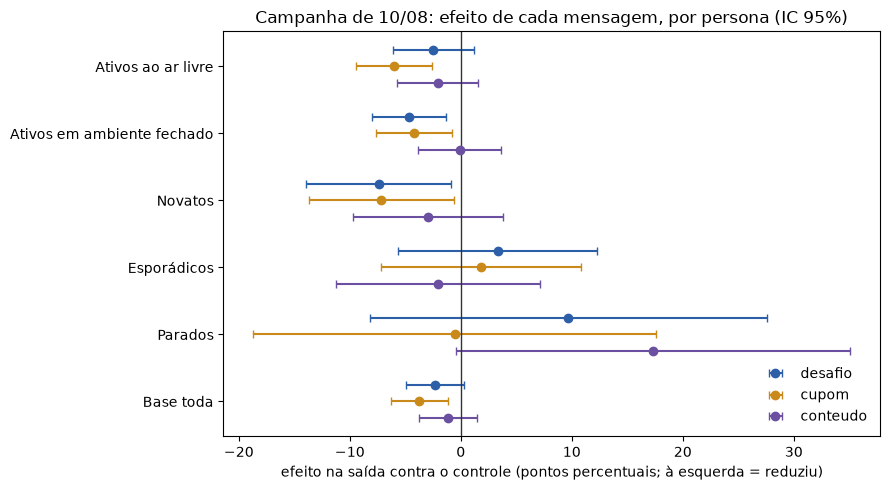

In [9]:
fig, ax = plt.subplots(figsize=(9, 5))
nomes = ORDEM + ["Base toda"]
for i, b in enumerate(["desafio", "cupom", "conteudo"]):
    d = efeitos[efeitos["mensagem"] == b].set_index("persona").reindex(nomes)
    y = np.arange(len(nomes)) + (i - 1) * 0.25
    ax.errorbar(d["efeito pp"], y, xerr=[d["efeito pp"] - d["IC 95% de"], d["até"] - d["efeito pp"]],
                fmt="o", capsize=3, label=b, color=["#2d5fa8", "#c98a1b", "#6b4fa0"][i])
ax.axvline(0, color="#333", lw=1)
ax.set_yticks(range(len(nomes)), nomes); ax.invert_yaxis()
ax.set_xlabel("efeito na saída contra o controle (pontos percentuais; à esquerda = reduziu)")
ax.set_title("Campanha de 10/08: efeito de cada mensagem, por persona (IC 95%)")
ax.legend(frameon=False, loc="lower right")
plt.tight_layout(); plt.savefig(FIGS / "campanha_efeito.png", dpi=150); plt.show()

**O que a campanha mostra.**
- **Ativos e novatos respondem.** O cupom reduz a saída dos ativos ao ar livre (−6,0 pp) e dos de ambiente fechado (−4,2 pp); o desafio reduz a dos de ambiente fechado (−4,7 pp) e a dos novatos (−7,4 pp), sem custo.
- **Esporádicos não respondem a push e e-mail.** Nenhuma das três mensagens mudou a saída, e o intervalo (±9 pp) não permite dizer que alguma funcione. "Risco alto não basta, o contato precisa mudar o desfecho" (Aula 5): para eles, push e e-mail não mudam.
- **Parados podem ser *sleeping dogs*.** Nenhuma mensagem reduziu a saída; conteúdo e desafio aumentaram (+17 e +10 pp), mas com poucos casos o intervalo inclui o zero. O sinal é de cautela, não de prova.

## Passo 5 · O cupom se paga?

O enunciado lembra que "uma oferta dada a quem ficaria de qualquer jeito é custo sem retorno". Para cada persona em que o cupom teve efeito, comparamos o custo de reter **uma** pessoa (custo médio do cupom ÷ efeito) com o valor potencial dela.

In [10]:
cupom = []
for s in ORDEM:
    d = seg[seg["segmento"] == s]
    custo_medio = (d["plano"] == "mensal").mean() * CUSTO["cupom_mensal"] + (d["plano"] == "anual").mean() * CUSTO["cupom_anual"]
    e = efeitos[(efeitos["persona"] == s) & (efeitos["mensagem"] == "cupom")].iloc[0]
    por_retido = custo_medio / (-e["efeito pp"] / 100) if e["efeito pp"] < 0 else np.nan
    cupom.append({"persona": s, "custo médio do cupom (R$)": custo_medio, "efeito pp": e["efeito pp"],
                  "significativo": e["significativo"], "custo por pessoa retida (R$)": por_retido,
                  "valor potencial mediano (R$)": valor.loc[s, "valor_potencial"]})
cupom = pd.DataFrame(cupom).set_index("persona")
cupom["se paga?"] = cupom["custo por pessoa retida (R$)"] < cupom["valor potencial mediano (R$)"]
cupom.round(1)

,custo médio do cupom (R$),efeito pp,significativo,custo por pessoa retida (R$),valor potencial mediano (R$),se paga?
persona,,,,,,
Ativos ao ar livre,30.10,-6.00,True,502.40,364.50,False
Ativos em ambiente fechado,30.50,-4.20,True,726.40,474.60,False
Novatos,31.70,-7.20,True,441.90,474.60,True
Esporádicos,26.90,1.80,False,NaN,322.50,False
Parados,25.10,-0.60,False,"4,523.40",322.50,False


**Leitura.** Nos ativos, o cupom funciona, mas reter uma pessoa custa mais do que ela vale: o desconto vai sobretudo para quem ficaria de qualquer jeito. Nos novatos, ele se paga por pouco (R$ 442 por pessoa retida contra R$ 475 de valor), mas o desafio, que é grátis, teve o mesmo efeito. **Decisão: sem cupom em massa**; desconto só na conversa do CS, para quem já desligou a renovação.

## Passo 6 · De cinco segmentos para quatro personas

O guia do aluno pede, para a semana 5, **3 a 4 segmentos** descritos com cartões de persona. Juntamos os dois grupos de ativos numa persona só: os dois têm risco baixo, valor alto e o mesmo lugar na matriz (Proteger). A diferença entre eles, que o cupom move os de ar livre e o desafio move os de ambiente fechado, fica registrada no cartão.

In [11]:
seg["persona_grupo"] = seg["segmento"].astype(str).replace({"Ativos ao ar livre": "Ativos", "Ativos em ambiente fechado": "Ativos"})
pode = seg[seg["podia_sair"]]
GRUPOS = ["Esporádicos", "Parados", "Novatos", "Ativos"]
val4 = pd.DataFrame([validar(pode["persona_grupo"] == g, g) for g in GRUPOS]).set_index("recorte")
val4.insert(0, "n na base", seg["persona_grupo"].value_counts().reindex(GRUPOS).values)
val4.insert(1, "% da base", val4["n na base"] / len(seg) * 100)

valor4 = seg.groupby("persona_grupo").agg(
    tempo_casa_dias=("tempo_casa_dias", "median"), pct_anual=("plano", lambda s: (s == "anual").mean() * 100),
    treinos_semana=("treinos_semana", "median"), dias_sem_treino=("dias_sem_treino", "median"),
    pago_ate_corte=("pago_ate_corte", "median"), valor_potencial=("valor_potencial", "median")).reindex(GRUPOS)
valor4["valor perdido em 60 dias (R$)"] = pode.assign(v=pode["saiu_60d"] * pode["valor_potencial"]).groupby("persona_grupo")["v"].sum()

c = camp[camp["podia_sair"]].assign(persona_grupo=lambda d: d["segmento"].astype(str).replace(
    {"Ativos ao ar livre": "Ativos", "Ativos em ambiente fechado": "Ativos"}))
d = c[c["persona_grupo"] == "Ativos"]
ctl = d.loc[d["braco"] == "controle", "saiu_pos"]
print("Ativos juntos, efeito contra o controle (pp, IC 95%):",
      {b: tuple(round(x, 1) for x in efeito(d.loc[d["braco"] == b, "saiu_pos"], ctl)) for b in ["desafio", "cupom", "conteudo"]})
display(val4.round(1)); display(valor4.round(1))

Ativos juntos, efeito contra o controle (pp, IC 95%): {'desafio': (np.float64(-3.4), np.float64(-5.9), np.float64(-0.9)), 'cupom': (np.float64(-5.1), np.float64(-7.6), np.float64(-2.7)), 'conteudo': (np.float64(-1.1), np.float64(-3.8), np.float64(1.5))}


,n na base,% da base,n (podia sair),saída grupo %,saída resto %,diferença pp,cobertura %
recorte,,,,,,,
Esporádicos,2858,20.40,1037,51.80,15.20,36.50,36.80
Parados,835,6.00,236,66.90,19.00,48.00,10.80
Novatos,1664,11.90,1027,18.10,21.00,-2.90,12.70
Ativos,8675,61.80,4789,12.10,38.30,-26.20,39.60


,tempo_casa_dias,pct_anual,treinos_semana,dias_sem_treino,pago_ate_corte,valor_potencial,valor perdido em 60 dias (R$)
persona_grupo,,,,,,,
Esporádicos,315.00,82.40,0.50,20.00,299.90,322.50,"202,274.50"
Parados,506.00,99.20,0.00,167.00,599.80,322.50,"53,040.40"
Novatos,28.00,38.30,0.90,2.00,79.80,474.60,"92,042.40"
Ativos,298.00,51.50,2.40,2.00,339.10,364.50,"275,392.20"


## Passo 7 · A matriz valor × risco e a prioridade

**Risco** = saída do grupo entre quem podia sair, a diferença para o resto e a cobertura. **Valor** = critério potencial (Passo 3). Cada persona vai para um só lugar. O guia pede ainda a **priorização preliminar** em duas classes: ação **imediata** ou **monitoramento**.

In [12]:
personas = pd.DataFrame({
    "persona": ["Esporádico com renovação à vista", "Pagante parado", "Novato recém-chegado", "Ativo regular"],
    "persona_grupo": GRUPOS,
    "valor": ["alto", "médio", "médio", "alto"],
    "risco": ["alto", "alto", "baixo", "baixo"],
    "lugar": ["Priorizar", "Não acordar", "Manter", "Proteger"],
    "prioridade": ["imediata", "monitoramento", "monitoramento", "monitoramento"],
    "canal": ["CS + WhatsApp", "nenhum", "push", "push + e-mail"],
}).set_index("persona_grupo")
personas = personas.join(val4[["n na base", "% da base", "n (podia sair)", "saída grupo %", "saída resto %", "diferença pp", "cobertura %"]])
personas = personas.join(valor4)
personas.reset_index().set_index("persona").round(1)

,persona_grupo,valor,risco,lugar,prioridade,canal,n na base,% da base,n (podia sair),saída grupo %,saída resto %,diferença pp,cobertura %,tempo_casa_dias,pct_anual,treinos_semana,dias_sem_treino,pago_ate_corte,valor_potencial,valor perdido em 60 dias (R$)
persona,,,,,,,,,,,,,,,,,,,,
Esporádico com renovação à vista,Esporádicos,alto,alto,Priorizar,imediata,CS + WhatsApp,2858,20.40,1037,51.80,15.20,36.50,36.80,315.00,82.40,0.50,20.00,299.90,322.50,"202,274.50"
Pagante parado,Parados,médio,alto,Não acordar,monitoramento,nenhum,835,6.00,236,66.90,19.00,48.00,10.80,506.00,99.20,0.00,167.00,599.80,322.50,"53,040.40"
Novato recém-chegado,Novatos,médio,baixo,Manter,monitoramento,push,1664,11.90,1027,18.10,21.00,-2.90,12.70,28.00,38.30,0.90,2.00,79.80,474.60,"92,042.40"
Ativo regular,Ativos,alto,baixo,Proteger,monitoramento,push + e-mail,8675,61.80,4789,12.10,38.30,-26.20,39.60,298.00,51.50,2.40,2.00,339.10,364.50,"275,392.20"


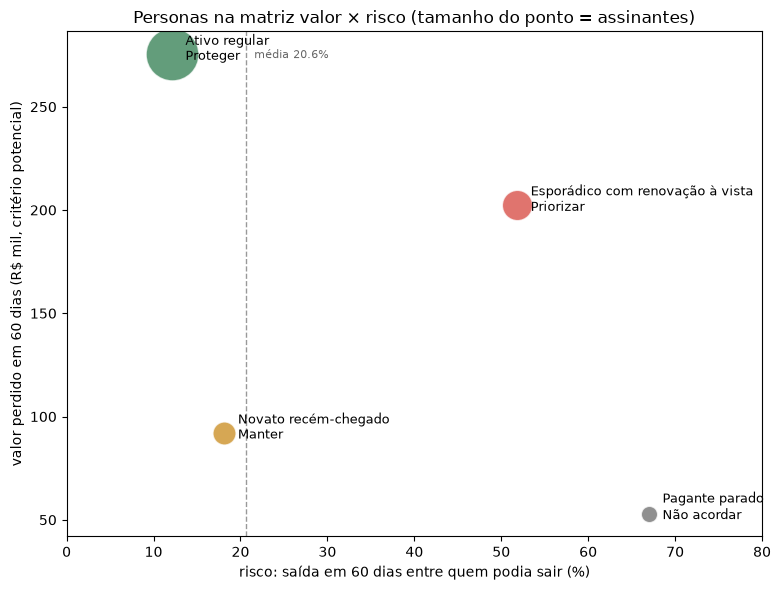

In [13]:
fig, ax = plt.subplots(figsize=(8, 6))
media = pode["saiu_60d"].mean() * 100
for s, r in personas.iterrows():
    y = r["valor perdido em 60 dias (R$)"] / 1000
    ax.scatter(r["saída grupo %"], y, s=r["n na base"] / 6, color=CORES.get(s, "#2f7d4f"), alpha=.75, edgecolor="white")
    ax.annotate(f"{r['persona']}\n{r['lugar']}", (r["saída grupo %"], y), textcoords="offset points", xytext=(10, -4), fontsize=9)
ax.axvline(media, color="#999", ls="--", lw=1)
ax.text(media + 1, ax.get_ylim()[1] * .97, f"média {media:.1f}%", fontsize=8, color="#666", va="top")
ax.set_xlabel("risco: saída em 60 dias entre quem podia sair (%)")
ax.set_ylabel("valor perdido em 60 dias (R$ mil, critério potencial)")
ax.set_title("Personas na matriz valor × risco (tamanho do ponto = assinantes)")
ax.set_xlim(0, 80)
plt.tight_layout(); plt.savefig(FIGS / "matriz_valor_risco.png", dpi=150); plt.show()

## Passo 8 · O orçamento do mês

Os tetos e custos são os do enunciado: WhatsApp a R$ 0,40 (até 1.500 por mês), CS a R$ 18 (até 300), e-mail a R$ 0,01, push sem custo (até 1 por semana). A janela de 60 dias vira volume mensal dividindo por 2. Não usamos IA generativa no envio; se usarmos, o custo entra nesta conta.

Para o desconto oferecido pelo CS, contamos o pior caso: todos os atendidos aceitam.

In [14]:
mes = lambda m: int(round(m.sum() / 2))
esp_pode = pode[pode["segmento"] == "Esporádicos"]
cs_mes = mes(esp_pode["renov_desligada"])
wpp_mes = mes(~esp_pode["renov_desligada"] & (esp_pode["dias_sem_treino"] >= 8))
cs_anual = mes(esp_pode["renov_desligada"] & (esp_pode["plano"] == "anual"))
cs_mensal = cs_mes - cs_anual
n_seg = seg["segmento"].value_counts()
orc = pd.DataFrame([
    ("Esporádico com renovação à vista", "CS no intervalo entre desligar a renovação e expirar", cs_mes, CUSTO["cs"]),
    ("Esporádico com renovação à vista", "oferta do CS: 1 mês grátis (anual)", cs_anual, CUSTO["cupom_anual"]),
    ("Esporádico com renovação à vista", "oferta do CS: 30% por 3 meses (mensal)", cs_mensal, CUSTO["cupom_mensal"]),
    ("Esporádico com renovação à vista", "WhatsApp: renovação ligada e 8+ dias sem treino", wpp_mes, CUSTO["whatsapp"]),
    ("Novato recém-chegado", "push de desafio na 1ª semana", int(n_seg["Novatos"]), CUSTO["push"]),
    ("Ativo regular", "push de desafio + e-mail de indicação", int(n_seg["Ativos ao ar livre"] + n_seg["Ativos em ambiente fechado"]), CUSTO["email"]),
    ("Pagante parado", "nenhum contato", 0, 0.0),
], columns=["persona", "ação", "contatos por mês", "custo unitário (R$)"])
orc["custo no mês (R$)"] = orc["contatos por mês"] * orc["custo unitário (R$)"]
display(orc.round(2))
print(f"CS: {cs_mes} de {TETO['cs']} | WhatsApp: {wpp_mes} de {TETO['whatsapp']} | "
      f"total: R$ {orc['custo no mês (R$)'].sum():,.0f} de R$ {TETO['orcamento']:,}")

,persona,ação,contatos por mês,custo unitário (R$),custo no mês (R$)
0,Esporádico com renovação à vista,CS no intervalo entre desligar a renovação e e...,226,18.00,"4,068.00"
1,Esporádico com renovação à vista,oferta do CS: 1 mês grátis (anual),188,25.00,"4,700.00"
2,Esporádico com renovação à vista,oferta do CS: 30% por 3 meses (mensal),38,35.91,"1,364.58"
3,Esporádico com renovação à vista,WhatsApp: renovação ligada e 8+ dias sem treino,176,0.40,70.40
4,Novato recém-chegado,push de desafio na 1ª semana,1664,0.00,0.00
5,Ativo regular,push de desafio + e-mail de indicação,8675,0.01,86.75
6,Pagante parado,nenhum contato,0,0.00,0.00


CS: 226 de 300 | WhatsApp: 176 de 1500 | total: R$ 10,290 de R$ 40,000


**Leitura.** O teto pesa mais que o custo, como o enunciado avisa: o plano usa 3 de cada 4 atendimentos do CS, só 176 dos 1.500 WhatsApps e gasta cerca de R$ 10 mil dos R$ 40 mil. A lista de quem precisa de contato caro é menor que o teto: dar WhatsApp a esporádicos com a renovação ligada e uso em dia seria contato para quem já sai menos que a média. Não propomos gastar o resto em cupom, porque o Passo 5 mostrou que ele não se paga. A sobra fica para os testes, que precisam de grupo controle em toda ação nova.

## Passo 9 · Hipóteses de drivers de churn

O guia pede hipóteses de drivers por segmento. Seguimos o formato da Aula 2: afirmação causal, métrica e critério de refutação definido antes. Os números abaixo são o primeiro teste de cada uma com a base que temos.

In [15]:
e = pode[pode["persona_grupo"] == "Esporádicos"]
print("Esporádicos, saída por dias sem treino em 31/07:")
display(e.groupby(e["dias_sem_treino"] >= 8)["saiu_60d"].agg(["size", "mean"]).rename(index={False: "até 7 dias", True: "8 dias ou mais"}).round(3))
p = c[c["persona_grupo"] == "Parados"]
print("Parados, qualquer mensagem contra o controle (pp, IC 95%):",
      tuple(round(x, 1) for x in efeito(p.loc[p["braco"] != "controle", "saiu_pos"], p.loc[p["braco"] == "controle", "saiu_pos"])))
a = c[c["persona_grupo"] == "Ativos"]
for plano in ["mensal", "anual"]:
    d = a[a["plano"] == plano]
    print(f"Ativos {plano}: cupom contra o controle (pp, IC 95%):",
          tuple(round(x, 1) for x in efeito(d.loc[d["braco"] == "cupom", "saiu_pos"], d.loc[d["braco"] == "controle", "saiu_pos"])),
          f"| n cupom {(d['braco'] == 'cupom').sum()}, controle {(d['braco'] == 'controle').sum()}")

Esporádicos, saída por dias sem treino em 31/07:


,size,mean
dias_sem_treino,,
até 7 dias,297,0.25
8 dias ou mais,740,0.63


Parados, qualquer mensagem contra o controle (pp, IC 95%): (np.float64(8.3), np.float64(-6.6), np.float64(23.2))
Ativos mensal: cupom contra o controle (pp, IC 95%): (np.float64(-5.6), np.float64(-8.2), np.float64(-3.1)) | n cupom 995, controle 1042
Ativos anual: cupom contra o controle (pp, IC 95%): (np.float64(-1.1), np.float64(-9.0), np.float64(6.7)) | n cupom 136, controle 160


| Persona | Hipótese (afirmação causal) | Métrica | Cai se… | Primeiro teste |
| :-- | :-- | :-- | :-- | :-- |
| Esporádico com renovação à vista | A queda de uso antes da renovação leva o assinante a não renovar | Saída na janela, por dias sem treino em 31/07 | quem está há 8+ dias sem treinar sair tanto quanto quem treinou na última semana | **Sobrevive:** 63% contra 25% |
| Pagante parado | Pagar sem usar faz o assinante sair quando o app o lembra disso | Saída de quem recebe mensagem contra o controle | a saída com mensagem não for maior que a do controle | **Em aberto:** +8,3 pp, IC de −6,6 a +23,2 |
| Novato recém-chegado | Sem hábito no primeiro mês, o novato sai; um desafio cria o hábito | Saída do novato com desafio contra o controle | o desafio não reduzir a saída | **Sobrevive:** −7,4 pp, IC de −13,9 a −0,9 |
| Ativo regular | O ativo mensal que sai sai por preço, não por falta de uso | Efeito do cupom no ativo mensal contra o anual | o cupom reduzir a saída igualmente nos dois planos | **Sobrevive:** mensal −5,6 pp (IC −8,2 a −3,1); anual −1,1 pp (IC −9,0 a +6,7) |

O driver do ativo conversa com a primeira lacuna do case, a subida do churn em 2026: o reajuste do mensal em 01/03 é um candidato a causa que a próxima etapa pode testar.

## Passo 10 · Gravar

In [16]:
saida = personas.reset_index()
saida.to_csv(PROC / "personas_31jul.csv", index=False)
efeitos.to_csv(FIGS / "campanha_efeitos.csv", index=False)
orc.to_csv(FIGS / "orcamento_mes.csv", index=False)
print("gravados: dados/processados/personas_31jul.csv, saidas/personas/campanha_efeitos.csv, orcamento_mes.csv e as duas figuras")

gravados: dados/processados/personas_31jul.csv, saidas/personas/campanha_efeitos.csv, orcamento_mes.csv e as duas figuras


## Limites

- **Associação não é causa**, fora da campanha. A campanha é o único efeito medido; as ações novas (CS no intervalo entre os avisos, WhatsApp, programa de indicação) são hipóteses a testar com grupo controle.
- **A janela da segmentação contém a campanha.** A saída de 60 dias depois de 31/07 mistura quem recebeu mensagem e quem não recebeu; como o efeito médio foi pequeno (−1 a −4 pp), a ordem dos riscos não muda.
- **Parados:** cada braço tem cerca de 55 pessoas que podiam sair; o sinal de *sleeping dog* não está provado.
- **Motivo da saída:** só ~10% respondem à pesquisa de saída, e só quem paga pelo site. O "por quê" não está na base.
- **Valor:** a margem de 12 meses supõe que quem fica, fica um ano. Para o mensal isso é otimista; o critério serve para comparar grupos, não como previsão de receita.
- **Idade e gênero** não entram em nenhuma decisão.